# Figure 6: melanoma spatial Hi-C and RNA

Fig. 6 applies Saturn to a melanoma section profiled by spatial Hi-C and RNA on the same DBiT chip (SpHIC117). After chip
rows 50 and 51 (a channel dip) are dropped, the section has 6,108 spots. The RNA target is GLM-PCA of the full 10x matrix
with log RNA depth regressed out. The Hi-C target is built from the chromatin layers themselves: the A/B compartment score
and the single-spot TAD insulation of every 500 kb bin, each regressed on log Hi-C reads.

The panels: the co-profiled section (a), the two isodepths and their domains (b), two genes along ρ$_{\mathrm{RNA}}$ (c),
A/B (d) and insulation (e) bins along ρ$_{\mathrm{HiC}}$, three bins whose genes, A/B and insulation change together (f),
chromatin-gene Granger coupling per domain against a circular-shift null (g), and two example bins along the isodepths (h).

**Conda env:** `spatialmultivelo`, CPU only. **Time:** about 15 min on a shared machine, most of it the fit (about 11 min on
8 threads); the per-domain Granger test takes a few minutes on 40 processes.

## Setup

The published fit ran with 8 torch threads and `OMP_NUM_THREADS` unset. A CPU fit depends on the thread count as well as
on the seed, so the thread variables are removed before numpy and torch are imported.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.pop(v, None)
import gzip, json
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from anndata.experimental import read_elem
from joblib import Parallel, delayed
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.io import mmread
from scipy.interpolate import griddata
from scipy.optimize import linear_sum_assignment
from scipy.spatial import cKDTree
from scipy.stats import f as fdist, rankdata, spearmanr

import saturn
from saturn import piecewise as pw
from saturn.domains import gaston_domains, choose_k, isodepth_bins
from saturn.plotting import spatial
from saturn.preprocess import scale_target, zscore_coords
from saturn.theme import MODALITY, DOMAIN, CMAP, ANCHOR, REFERENCE

saturn.theme.set_theme(7)
WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig6"; OUT.mkdir(parents=True, exist_ok=True)

C_RNA, C_HIC = MODALITY["RNA"], MODALITY["Hi-C"]
AXC = {"RNA": C_RNA, "HiC": C_HIC}
C_AB, C_IN = ANCHOR["rust"], ANCHOR["ochre"]                  # A/B compartment and insulation lines
INK, GRID = ANCHOR["ink"], ANCHOR["stone"]
DOM_COL = {**DOMAIN, "deep tumour": ANCHOR["teal"], "tumour": DOMAIN["deep tumour"], "non-tumour": DOMAIN["epidermis"]}
SUB = {"RNA": "ρ$_{\\mathrm{RNA}}$", "HiC": "ρ$_{\\mathrm{HiC}}$"}


def cbar(fig, ax, sc, label, on_top=False, ticks=None):
    """small colour bar to the right of a map"""
    cax = ax.inset_axes([1.03, 0.05, 0.05, 0.72] if on_top else [1.02, 0.1, 0.045, 0.8])
    cb = fig.colorbar(sc, cax=cax, ticks=ticks)
    cb.outline.set_linewidth(0.4); cb.ax.tick_params(labelsize=5.5, length=1.5, width=0.4)
    if on_top:
        cb.ax.set_title(label, fontsize=5.5, pad=2, loc="left")
    else:
        cb.set_label(label, fontsize=5.5, labelpad=1)


def bin_title(b):
    c_, se = b.split(":"); s0, e0 = (int(x) / 1e6 for x in se.split("-"))
    return f"{c_} {s0:g}–{e0:g} Mb"

## Spots and RNA

The spot table gives the in-tissue spots and their chip coordinates. Chip rows 50 and 51 are dropped. The RNA counts are
the full 10x matrix (62,700 genes), put in the spot order of the table.

In [2]:
with h5py.File(WORK / "melanoma_hic_spots.h5ad", "r") as f:
    obs = read_elem(f["obs"])
    coords_all = np.asarray(read_elem(f["obsm"]["spatial"]), float)
keep_spot = ~np.isin(coords_all[:, 1], [50, 51])
barcodes = np.array(obs.index[keep_spot], str)
coords = coords_all[keep_spot]
xy = coords
N = len(barcodes)

raw_bc = [l.strip() for l in gzip.open(WORK / "rna/barcodes.tsv.gz", "rt")]
genes = np.array([str(v) for v in pd.read_csv(WORK / "rna/features.tsv.gz", sep="\t", header=None)[1]])
X = sp.csr_matrix(mmread(WORK / "rna/matrix.mtx.gz").T)[pd.Index(raw_bc).get_indexer(pd.Index(barcodes))]
lib = np.asarray(X.sum(1)).ravel().clip(1)
print(f"{N} spots ({(~keep_spot).sum()} dropped in rows 50-51), {X.shape[1]} genes, median {np.median(lib):.0f} counts per spot")

6108 spots (160 dropped in rows 50-51), 62700 genes, median 1436 counts per spot


## Chromatin layers per 500 kb bin

Higashi and Fast-Higashi need their own environment and a GPU, so their outputs are read from `published/`: the 500 kb
A/B compartment z-scores (`scCompartment.hdf5`), the 100 kb single-spot insulation (`scTAD.hdf5`) and the log Hi-C reads
per spot (`read_count_all.npy`). The `i`-th cell of each file is the `i`-th spot of its `filelist.txt`.

In [3]:
def spot_names(path):
    return [os.path.basename(l.strip()).replace(".contact.tsv", "") for l in open(path) if l.strip()]


H5 = PUB / "higashi_500kb"
reads = pd.Series(np.load(H5 / "read_count_all.npy"), index=spot_names(H5 / "filelist.txt")).reindex(barcodes).values.astype(float)
with h5py.File(H5 / "scCompartment.hdf5", "r") as f:
    g = f["compartment_zscore"]; fl = spot_names(H5 / "filelist.txt")
    AB_all = np.stack([g[f"cell_{i}"][:] for i in range(len(fl))])[pd.Index(fl).get_indexer(pd.Index(barcodes))]
    ch, st, en = g["bin"]["chrom"][:].astype(str), g["bin"]["start"][:], g["bin"]["end"][:]
bin_names = np.array([f"{c}:{s}-{e}" for c, s, e in zip(ch, st, en)])

H1 = PUB / "higashi_100kb"
with h5py.File(H1 / "scTAD.hdf5", "r") as f:
    g = f["insulation"]; ich, ist = g["bin"]["chrom"][:].astype(str), g["bin"]["start"][:]
    ckeys = sorted([k for k in g.keys() if k.startswith("cell_")], key=lambda k: int(k.split("_")[1]))
    Ins = np.vstack([g[k][:] for k in ckeys]).astype(np.float32)
fl = spot_names(H1 / "filelist.txt")
Ins = Ins[pd.Index([fl[int(k.split("_")[1])] for k in ckeys]).get_indexer(pd.Index(barcodes))]

# the mean of the 100 kb insulation values inside each 500 kb bin, ignoring missing values
col = pd.Series(np.arange(len(bin_names)), index=bin_names).reindex(
    [f"{c}:{s - s % 500000}-{s - s % 500000 + 500000}" for c, s in zip(ich, ist)]).fillna(-1).values.astype(int)
ok = col >= 0
A = sp.csr_matrix((np.ones(ok.sum()), (np.where(ok)[0], col[ok])), shape=(len(ich), len(bin_names)))
fin = np.isfinite(Ins)
with np.errstate(invalid="ignore", divide="ignore"):
    IN_all = np.asarray((np.where(fin, Ins, 0) @ A) / (fin.astype(np.float32) @ A))
print(f"A/B {AB_all.shape}, insulation {Ins.shape} -> {IN_all.shape}")

A/B (6108, 5359), insulation (6108, 28760) -> (6108, 5359)


Each bin gets a gene score: the mean log-normalised expression of the protein-coding genes whose body or promoter (TSS
± 2 kb) overlaps it. Bins with at least 3 genes and insulation in every spot are kept.

In [4]:
bed = pd.read_csv(WORK / "protein_coding_genes_human.bed", sep="\t", header=None,
                  names=["chrom", "start", "end", "gene", "score", "strand"])
gidx = {g: i for i, g in enumerate(genes)}
bed = bed[bed.gene.isin(gidx)].copy()
bed["tss"] = np.where(bed.strand == "+", bed.start, bed.end)
by_chrom = {c: list(zip(s.start, s.end, s.tss - 2000, s.tss + 2000, s.gene)) for c, s in bed.groupby("chrom")}
b2g, b2n = {}, {}
for j, nm in enumerate(bin_names):
    c_, se = nm.split(":"); s_, e_ = (int(v) for v in se.split("-"))
    hit = {(gidx[gn], gn) for gs, ge, ps, pe, gn in by_chrom.get(c_, []) if (gs < e_ and ge > s_) or (ps < e_ and pe > s_)}
    if len(hit) >= 3:
        b2g[j] = sorted(i for i, _ in hit); b2n[j] = sorted(g for _, g in hit)

keep_bin = [b for b in sorted(b2g) if np.isfinite(IN_all[:, b]).all()]
med = np.median(np.maximum(np.asarray(X.sum(1)).ravel(), 1))
Xl = np.log1p(sp.diags(med / np.maximum(np.asarray(X.sum(1)).ravel(), 1)) @ X).tocsc()
S = np.column_stack([np.asarray(Xl[:, b2g[b]].mean(1)).ravel() for b in keep_bin]).astype(np.float32)
names = bin_names[keep_bin]
bin_genes = np.array([",".join(b2n[b][:6]) for b in keep_bin])
ABf, INf = (V[:, keep_bin].astype(np.float32).astype(float) for V in (AB_all, IN_all))   # stored as float32, as published
Sf = S.astype(float)
S25f = Sf[cKDTree(xy).query(xy, k=25)[1]].mean(1)          # noise-matched gene scores: mean over the 25 nearest spots
print(f"{len(keep_bin)} of {len(bin_names)} bins with >= 3 genes and complete insulation")

2558 of 5359 bins with >= 3 genes and complete insulation


## Targets

**RNA.** `saturn.preprocess.rna_glmpc_real` starts GLM-PCA from an unseeded random draw, so the published RNA target
cannot be regenerated; its 10 GLM-PCs are read from `published/`. A cubic in log RNA depth (counts over the genes detected
in at least 1% of spots) is regressed out and the target is rescaled.

**Hi-C.** Each A/B and insulation bin is regressed on a cubic in log Hi-C reads, z-scored, and each layer is weighted by
1/sqrt(number of bins) so the two layers count equally; the 10 leading PCs are the target.

In [5]:
def resid_cubic(M, r):
    z = (r - r.mean()) / r.std(); D = np.c_[np.ones_like(z), z, z ** 2, z ** 3]
    return M - D @ np.linalg.lstsq(D, M, rcond=None)[0]


pub = np.load(PUB / "targets_mel_hic_fh_dr50_51.npz", allow_pickle=True)
Y_RNA = pd.DataFrame(pub["Y_RNA"], index=pub["barcodes"].astype(str)).loc[barcodes].values
detected = np.asarray((X > 0).sum(0)).ravel() / N >= 0.01
depth_RNA = np.asarray(X[:, detected].sum(1)).ravel()
Y_RNA = scale_target(resid_cubic(np.asarray(Y_RNA, float), np.log(depth_RNA.astype(float).clip(1))), "global")

blocks = []
for M in (ABf, INf):
    M = resid_cubic(M, reads)
    M = M[:, M.std(0) > 1e-9]
    M = (M - M.mean(0)) / M.std(0); blocks.append(M / np.sqrt(M.shape[1]))
Xh = np.hstack(blocks); Xh -= Xh.mean(0)
U, sv, _ = np.linalg.svd(Xh, full_matrices=False)
Y_HiC = scale_target((U * sv)[:, :10], "global")
print(f"Hi-C target: 10 PCs = {100 * (sv[:10] ** 2).sum() / (sv ** 2).sum():.1f}% of variance; "
      f"|r| with log reads, PC1-5: {[round(abs(np.corrcoef(Y_HiC[:, i], reads)[0, 1]), 2) for i in range(5)]}")

Hi-C target: 10 PCs = 5.1% of variance; |r| with log reads, PC1-5: [0.0, 0.0, 0.0, 0.0, 0.0]


## Saturn fit

One isodepth per modality, seed 42, 3,000 refit epochs on all spots, 8 threads.

In [6]:
FIT = OUT / "fit"
if not (FIT / "axes.csv").exists():
    res = saturn.fit([Y_RNA, Y_HiC], zscore_coords(coords), ["RNA", "HiC"], seeds=[42], refit_all_epochs=3000,
                     device="cpu", threads=8)
    FIT.mkdir(exist_ok=True)
    pd.DataFrame(np.c_[coords, res.axes], columns=["x", "y", "d_RNA", "d_HiC"], index=barcodes).to_csv(FIT / "axes.csv")
    json.dump(res.summary(), open(FIT / "summary.json", "w"), indent=1, default=float)
    np.savez_compressed(FIT / "targets.npz", Y_RNA=Y_RNA, Y_HiC=Y_HiC, barcodes=barcodes)
axes_df = pd.read_csv(FIT / "axes.csv", index_col=0)
R2 = json.load(open(FIT / "summary.json"))["R2_whole"]
d = {m: axes_df[f"d_{m}"].values for m in ("RNA", "HiC")}
Y = {"RNA": Y_RNA, "HiC": Y_HiC}
print({m: round(R2[m]["full"], 3) for m in d}, " Spearman(rho_RNA, rho_HiC):", round(spearmanr(d["RNA"], d["HiC"])[0], 3))

{'RNA': 0.204, 'HiC': 0.587}  Spearman(rho_RNA, rho_HiC): 0.755


## Domains

GASTON's segmentation of each isodepth, with the number of domains at the kneedle elbow of the segmentation error curve.
An RNA domain is named by the marker programme it is most enriched for (z-score across domains, one programme per domain).
The Hi-C domains are named tumour and non-tumour by a melanocytic tumour score.

In [7]:
lab = {m: gaston_domains(d[m], Y[m], n_domains=choose_k(d[m], Y[m])[0]) for m in d}


def score(gs):
    cols = [gidx[g] for g in gs if g in gidx]
    return np.log1p(np.asarray(X[:, cols].sum(1)).ravel() / lib * 1e4)


DOM_MARKERS = {"epidermis": ["KRT10", "KRT1", "KRT14"], "plasma / immune": ["IGHG1", "IGHA1", "CD74"],
               "melanocytic tumour": ["DCT", "OCA2", "PMEL"], "deep tumour": ["FRMD5", "DPP6", "KCNMA1"]}
K = lab["RNA"].max() + 1
Z = pd.DataFrame({n: (lambda m: (m - m.mean()) / m.std())(np.array([score(gs)[lab["RNA"] == k].mean() for k in range(K)]))
                  for n, gs in DOM_MARKERS.items()})
r_, c_ = linear_sum_assignment(-Z.values)
names_dom = {"RNA": {int(k): Z.columns[j] for k, j in zip(r_, c_)}}
t = score(["DCT", "PMEL", "MLANA", "TYR", "FRMD5", "DPP6", "KCNMA1"])
mt = [t[lab["HiC"] == k].mean() for k in range(lab["HiC"].max() + 1)]
names_dom["HiC"] = {int(np.argmax(mt)): "tumour", int(np.argmin(mt)): "non-tumour"}
dcol = {m: np.array([DOM_COL[names_dom[m][k]] for k in range(lab[m].max() + 1)]) for m in d}
print("marker z per RNA domain:\n", Z.round(2).to_string())
for m in d:
    print(m, {names_dom[m][k]: int((lab[m] == k).sum()) for k in range(lab[m].max() + 1)})

marker z per RNA domain:
    epidermis  plasma / immune  melanocytic tumour  deep tumour
0       1.59             1.24               -1.68        -1.56
1       0.12            -0.51                0.94         0.20
2      -0.75             0.62                0.43         0.14
3      -0.96            -1.35                0.31         1.22
RNA {'epidermis': 653, 'melanocytic tumour': 1239, 'plasma / immune': 1960, 'deep tumour': 2256}
HiC {'non-tumour': 2346, 'tumour': 3762}


## Fig. 6a: spatial Hi-C and RNA co-profiling of the section

Panel a shows the co-profiled section (n = 6,108 spots). The figure builders have no plotting code for it, so it is not
drawn here.

## Fig. 6b: isodepths and domains

ρ$_{\mathrm{RNA}}$ and ρ$_{\mathrm{HiC}}$ with the R² of each modality's target, and the domains along each axis with the
spots per domain in the key. For the Hi-C domains the key also gives the Hi-C reads relative to the section median.

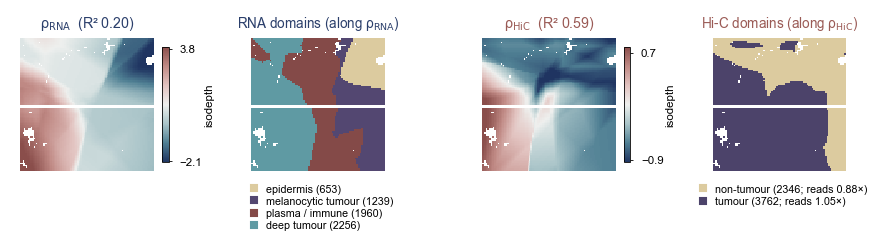

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(7.2, 1.9), gridspec_kw=dict(wspace=0.6))
for ax, m in ((axs[0], "RNA"), (axs[2], "HiC")):
    lo, hi = np.percentile(d[m], [1, 99])
    sc = spatial(ax, xy, d[m], cmap=CMAP["score"], vmin=lo, vmax=hi)
    cbar(fig, ax, sc, "isodepth", ticks=[np.ceil(lo * 10) / 10, np.floor(hi * 10) / 10])
    ax.set_title(f"{SUB[m]}  (R² {R2[m]['full']:.2f})", color=AXC[m], fontsize=6.8, pad=2)
for ax, m in ((axs[1], "RNA"), (axs[3], "HiC")):
    L = lab[m]; spatial(ax, xy, L, discrete=True, colors=list(dcol[m]))
    order = np.argsort([np.median(d[m][L == k]) for k in range(L.max() + 1)])
    lbl = lambda k: (f"{names_dom[m][k]} ({(L == k).sum()})" if m == "RNA" else
                     f"{names_dom[m][k]} ({(L == k).sum()}; reads {np.exp(np.median(reads[L == k]) - np.median(reads)):.2f}×)")
    ax.legend(handles=[Line2D([], [], ls="", marker="s", ms=3.2, color=dcol[m][k], label=lbl(k)) for k in order],
              fontsize=5.2, loc="upper center", bbox_to_anchor=(0.5, -0.02), borderaxespad=0, handletextpad=0.1,
              labelspacing=0.2)
    ax.set_title(f"{'RNA' if m == 'RNA' else 'Hi-C'} domains (along {SUB[m]})", color=AXC[m], fontsize=6.5, pad=2)
plt.show()

### Chromatin bins that track ρ$_{\mathrm{HiC}}$

For every bin, the Spearman correlation of its A/B or insulation value with ρ$_{\mathrm{HiC}}$, with Hi-C reads partialled
out: every series is rank-transformed and residualised on rank(reads). The null is 200 rotations of the axis about the section
centre (nearest-spot interpolation), residualised the same way; P is two-sided. The bins of panels d and e are the two
per layer that track ρ$_{\mathrm{HiC}}$ most strongly.

In [9]:
def rotated_fields(xy, v, n, rng):
    """n rotated copies of v: spatial autocorrelation kept, alignment with the tissue removed"""
    c = xy.mean(0); out = []
    for _ in range(n):
        th = rng.uniform(0, 2 * np.pi); Rm = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
        out.append(griddata((xy - c) @ Rm.T + c, v, xy, method="nearest"))
    return np.array(out)


Pz = (lambda Zr: Zr @ np.linalg.pinv(Zr))(np.c_[np.ones(N), rankdata(reads)])


def resid_z(M):
    M = np.apply_along_axis(rankdata, 0, np.atleast_2d(M.T).T).astype(float)
    M = M - Pz @ M; M -= M.mean(0)
    return M / np.linalg.norm(M, axis=0).clip(1e-12)


rng = np.random.default_rng(0); rows = []
for m in ("HiC",):
    Q = resid_z(np.column_stack([d[m]] + list(rotated_fields(xy, d[m], 200, rng))))
    for L, V in (("AB", ABf), ("insulation", INf)):
        r = resid_z(V).T @ Q
        p = ((np.abs(r[:, 1:]) >= np.abs(r[:, :1])).sum(1) + 1) / 201
        rows.append(pd.DataFrame(dict(axis=m, layer=L, bin=names, r=r[:, 0], p_rot=p)))
track = pd.concat(rows, ignore_index=True); track.to_csv(OUT / "bins_vs_rho_partial.csv", index=False)
print(track.groupby(["axis", "layer"]).p_rot.apply(lambda p: f"{(p < 0.05).sum()}/{len(p)}").to_string())

axis  layer     
HiC   AB            1600/2558
      insulation     796/2558


### Fitted functions

Panels c to e draw each feature in three columns: the measured value per spot, the fitted function at every spot, and the
fitted function along the isodepth with the bin means (25 bins) coloured by domain. Genes get a per-domain Poisson fit
along ρ$_{\mathrm{RNA}}$, chromatin bins a per-domain Gaussian fit along ρ$_{\mathrm{HiC}}$; a slope is kept where the
test gives P < 0.1.

In [10]:
def along(ax, m, L, cols, bx, by, blab, curve, ylabel):
    for k in range(L.max() + 1):
        s_ = blab == k
        ax.scatter(bx[s_], by[s_], s=6, color=cols[k], lw=0.3, edgecolor=INK, zorder=3)
        xs = np.linspace(d[m][L == k].min(), d[m][L == k].max(), 20)
        ax.plot(xs, curve(k, xs), color=cols[k], lw=1.3, zorder=2)
    for b in sorted([d[m][L == k].max() for k in range(L.max() + 1)])[:-1]:
        ax.axvline(b, color=GRID, lw=0.4, ls=(0, (2, 2)), zorder=1)
    ax.set_xlabel(SUB[m], color=AXC[m], labelpad=1); ax.set_ylabel(ylabel, labelpad=1); ax.tick_params(labelsize=5.5, pad=1)


def gene_feature(fig, cells, gname, sub):
    m, L = "RNA", lab["RNA"]; c = np.asarray(X[:, gidx[gname]].todense()).ravel().astype(float)
    sl, it = (v[0] for v in pw.fit_poisson(c[:, None], lib, L, d[m], t=0.1))
    bi, _, kp = isodepth_bins(d[m], 25)
    db = np.array([d[m][bi == b].mean() for b in kp])
    yb = np.array([c[bi == b].sum() for b in kp]) / np.maximum(np.array([lib[bi == b].sum() for b in kp]), 1)
    lb = np.array([np.bincount(L[bi == b], minlength=L.max() + 1).argmax() for b in kp])
    r2 = 1 - ((yb - np.exp(it[lb] + sl[lb] * db)) ** 2).sum() / max(((yb - yb.mean()) ** 2).sum(), 1e-12)
    v, fitv = np.log1p(c / lib * 1e4), np.log1p(np.exp(it[L] + sl[L] * d[m]) * 1e4)
    lo, hi = np.percentile(np.r_[v, fitv], [2, 99])
    a1, a2, a3 = (fig.add_subplot(cc) for cc in cells); o = np.argsort(v)
    spatial(a1, xy[o], v[o], cmap=CMAP["expression"], vmin=lo, vmax=hi)
    sc = spatial(a2, xy, fitv, cmap=CMAP["expression"], vmin=lo, vmax=hi); cbar(fig, a2, sc, "log\nCP10k", on_top=True)
    a1.set_title(f"{gname}\n{sub}", fontsize=6.0, pad=2, color=C_RNA, loc="left")
    along(a3, m, L, dcol[m], db, np.log1p(yb * 1e6), lb, lambda k, xs: np.log1p(np.exp(it[k] + sl[k] * xs) * 1e6), "log(CPM+1)")
    ns = int((np.abs(sl) > 1e-9).sum())
    a3.set_title(f"fitted function · R² {r2:.2f}\n{ns}/{len(sl)} domains sloped", fontsize=5.8, pad=2)
    return a1, a2, dict(R2=round(float(r2), 3), n_sloped=ns)


def bin_feature(fig, cells, layer, b, m="HiC"):
    key, lname = {"AB": (ABf, "A/B compartment"), "insulation": (INf, "insulation")}[layer]
    L = lab[m]; j = list(names).index(b); v = key[:, j]
    sl, it = (x[0] for x in pw.fit_gauss(v[:, None], L, d[m], t=0.1)); fitv = it[L] + sl[L] * d[m]
    q = np.quantile(d[m], np.linspace(0, 1, 26)); bi = np.clip(np.digitize(d[m], q[1:-1]), 0, 24)
    xb = np.array([d[m][bi == k].mean() for k in range(25)]); yb = np.array([v[bi == k].mean() for k in range(25)])
    lb = np.array([np.bincount(L[bi == k], minlength=L.max() + 1).argmax() for k in range(25)])
    r2 = 1 - ((yb - (it[lb] + sl[lb] * xb)) ** 2).sum() / ((yb - yb.mean()) ** 2).sum()
    lo, hi = np.percentile(v, [2, 98])
    a1, a2, a3 = (fig.add_subplot(cc) for cc in cells)
    spatial(a1, xy, v, cmap=CMAP["score"], vmin=lo, vmax=hi)
    sc = spatial(a2, xy, fitv, cmap=CMAP["score"], vmin=lo, vmax=hi); cbar(fig, a2, sc, "A/B" if layer == "AB" else "insulation", on_top=True)
    a1.set_title(f"{lname} {bin_title(b)}\n{', '.join(bin_genes[j].split(',')[:3])}", fontsize=6.0, pad=2, color=C_HIC, loc="left")
    along(a3, m, L, dcol[m], xb, yb, lb, lambda k, xs: it[k] + sl[k] * xs, "compartment score" if layer == "AB" else "insulation score")
    r = track[(track.axis == m) & (track.layer == layer)].set_index("bin").loc[b]
    a3.set_title(f"fitted function · R² {r2:.2f}\nrotation p {r.p_rot:.3f}", fontsize=5.8, pad=2)
    return a1, a2, dict(R2_bins=round(float(r2), 3), r=round(float(r.r), 3), p=float(r.p_rot))


def top_bins(layer, m="HiC", n=2):
    s_ = track[(track.axis == m) & (track.layer == layer) & (track.p_rot < 0.05)]
    return list(s_.reindex(s_.r.abs().sort_values(ascending=False).index).bin[:n])



def feature_row(items):
    """one row of two features, three columns each"""
    fig = plt.figure(figsize=(7.2, 1.75))
    gs = GridSpec(1, 11, figure=fig, width_ratios=[1, 0.05, 1, 0.98, 0.88, 0.28, 1, 0.05, 1, 0.98, 0.88], wspace=0,
                  left=0.06, right=0.99, top=0.76, bottom=0.2)
    st = {}
    for j, (kind, name, sub) in enumerate(items):
        cells = (gs[0, 6 * j], gs[0, 6 * j + 2], gs[0, 6 * j + 4])
        a1, a2, st[name] = gene_feature(fig, cells, name, sub) if kind == "gene" else bin_feature(fig, cells, kind, name)
        a1.text(0.5, -0.04, "measured" if kind == "gene" else "measured (per spot)", transform=a1.transAxes, ha="center", va="top", fontsize=5.5)
        a2.text(0.5, -0.04, "fitted function", transform=a2.transAxes, ha="center", va="top", fontsize=5.5)
    plt.show()
    return pd.DataFrame(st).T

## Fig. 6c: KRT10 and DCT along ρ$_{\mathrm{RNA}}$

Per-domain Poisson fits; titles give the R² of the fit to the bin means and the number of sloped domains.

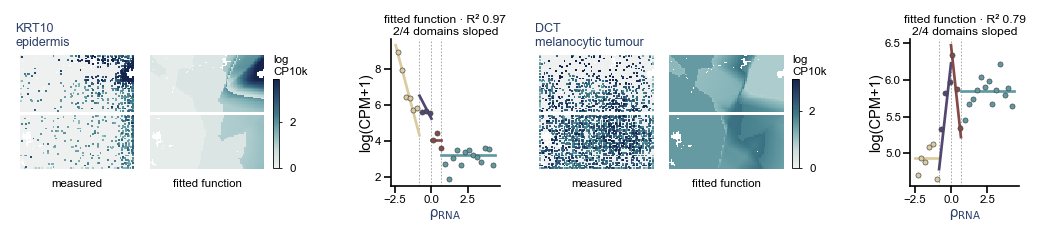

,R2,n_sloped
KRT10,0.965,2.0
DCT,0.785,2.0


In [11]:
feature_row([("gene", "KRT10", "epidermis"), ("gene", "DCT", "melanocytic tumour")])

## Fig. 6d: A/B compartment of two bins along ρ$_{\mathrm{HiC}}$

Per-domain Gaussian fits; titles name the genes of the bin and give R² and the two-sided rotation P (200 rotations). These
bins are in-sample: ρ$_{\mathrm{HiC}}$ is built from them.

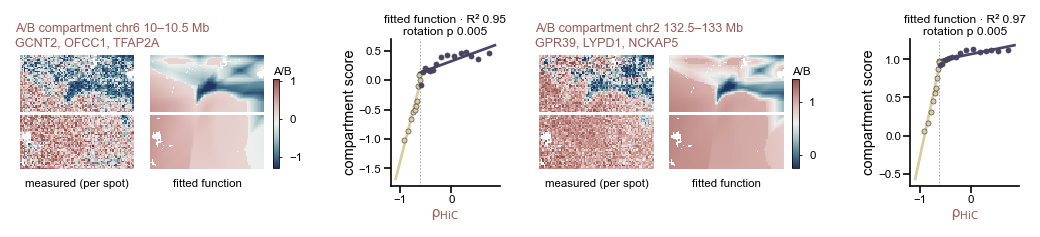

,R2_bins,r,p
chr6:10000000-10500000,0.949,0.616,0.004975
chr2:132500000-133000000,0.971,0.616,0.004975


In [12]:
feature_row([("AB", b, None) for b in top_bins("AB")])

## Fig. 6e: insulation of two bins along ρ$_{\mathrm{HiC}}$

As d, for the insulation layer.

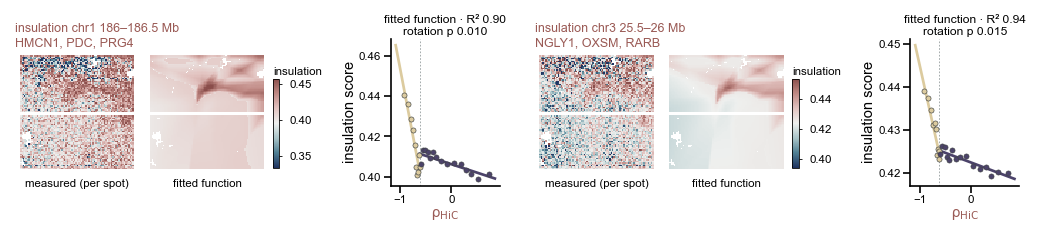

,R2_bins,r,p
chr1:186000000-186500000,0.896,-0.413,0.009950
chr3:25500000-26000000,0.944,-0.404,0.014925


In [13]:
feature_row([("insulation", b, None) for b in top_bins("insulation")])

## Granger test of one bin

The Granger test of one bin: spots ordered by ρ are cut into 30 equal-count windows; the window means of the chromatin
value and of the bin's gene score are detrended on a cubic in ρ; an F-test asks whether the lagged chromatin series
improves the prediction of the gene series (chromatin → gene) and the reverse (gene → chromatin), at lags 1 to 3. The
minimum P over lags is Bonferroni-corrected over lags and directions. The gene score is averaged over each spot's 25
nearest spots first, so that it is as smooth as the Higashi-imputed chromatin series (noise-matched genes).

In [14]:
LAGS, NBIN = (1, 2, 3), 30


def granger_p(y, x, lag):
    """F-test: does lagged x improve the prediction of y over lagged y alone?"""
    n = len(y) - lag
    if n < 3 * lag + 4:
        return np.nan
    Yv = y[lag:]
    Ly = np.column_stack([y[lag - k: -k] for k in range(1, lag + 1)])
    Lx = np.column_stack([x[lag - k: -k] for k in range(1, lag + 1)])
    one = np.ones((n, 1))
    rss = lambda Am: float(((Yv - Am @ np.linalg.lstsq(Am, Yv, rcond=None)[0]) ** 2).sum())
    r0, r1 = rss(np.hstack([one, Ly])), rss(np.hstack([one, Ly, Lx]))
    df2 = n - (1 + 2 * lag)
    if df2 <= 0 or r1 <= 0 or not np.isfinite(r0 + r1):
        return np.nan
    F = ((r0 - r1) / lag) / (r1 / df2)
    return float(fdist.sf(F, lag, df2)) if F > 0 else 1.0


def pair_p(g, c):
    """chromatin -> gene P, gene -> chromatin P (min over lags, Bonferroni over lags x directions), best chromatin -> gene lag"""
    m = 2 * len(LAGS)
    pf = [granger_p(g, c, L) for L in LAGS]; pr = [granger_p(c, g, L) for L in LAGS]
    f = np.nanmin(pf) if np.any(np.isfinite(pf)) else np.nan
    r = np.nanmin(pr) if np.any(np.isfinite(pr)) else np.nan
    return min(f * m, 1.0), min(r * m, 1.0), int(np.nanargmin(pf) + 1) if np.any(np.isfinite(pf)) else -1


def bh(p):
    p = np.asarray(p, float); okp = np.isfinite(p); q = np.full(p.shape, np.nan)
    v = p[okp]; o = np.argsort(v); n = len(v)
    qq = np.minimum.accumulate((v[o] * n / (np.arange(n) + 1))[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(qq, 1.0); q[okp] = out
    return q


def detrend3(V, r):
    z = (r - r.mean()) / r.std(); Am = np.column_stack([z ** k for k in range(4)])
    return V - Am @ np.linalg.lstsq(Am, V, rcond=None)[0]

### Per-bin Granger tests along the full isodepth

Every bin on the whole axis (all spots), with BH over bins per axis and layer. Panel h reads its P, lag and q here.

In [15]:
rows = []
for m in ("RNA", "HiC"):
    E = np.array_split(np.argsort(d[m]), NBIN); rb = np.array([d[m][e].mean() for e in E])
    Gb = detrend3(np.vstack([S25f[e].mean(0) for e in E]), rb)
    for L, C in (("A/B", ABf), ("insulation", INf)):
        Cb = detrend3(np.vstack([C[e].mean(0) for e in E]), rb)
        P = np.array([pair_p(Gb[:, j], Cb[:, j]) for j in range(Cb.shape[1])], float)
        rows.append(pd.DataFrame(dict(axis=m, layer=L, bin=names, genes=bin_genes, p_c2g=P[:, 0], p_g2c=P[:, 1],
                                      lag_c2g=P[:, 2].astype(int), q_c2g=bh(P[:, 0]), q_g2c=bh(P[:, 1]))))
per_bin = pd.concat(rows, ignore_index=True); per_bin.to_csv(OUT / "granger_per_bin.csv", index=False)
per_bin.groupby(["axis", "layer"])[["q_c2g", "q_g2c"]].apply(lambda s_: (s_ < 0.05).sum())

q_c2g  q_g2c
axis layer                   
HiC  A/B             0      3
     insulation      0      0
RNA  A/B             0      0
     insulation      2      0

## Fig. 6f: three bins whose genes, A/B and insulation change together

Bins in which the genes and A/B change in the same direction and insulation in the opposite direction in at least two
domains (slope signs per domain printed below). Each row: the fitted function at every spot
of the bin's genes, its A/B compartment and its insulation (per-domain Gaussian fit along ρ), and the three fitted
functions (lines) over 25 equal-count windows (dots), each z-scored on the window means.

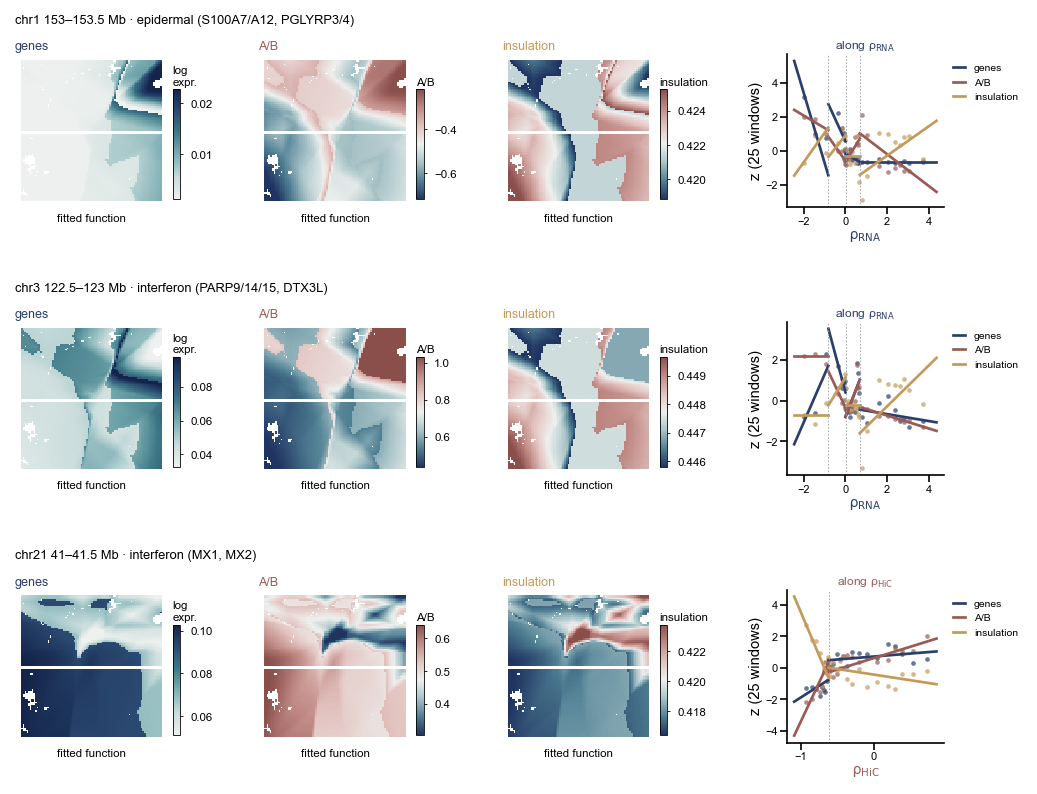

,axis,bin,domains_with_pattern,n
0,RNA,chr1 153–153.5 Mb,"epidermis, melanocytic tumour",2
1,RNA,chr3 122.5–123 Mb,"melanocytic tumour, deep tumour",2
2,HiC,chr21 41–41.5 Mb,"non-tumour, tumour",2


In [16]:
CIS_EX = [("RNA", "chr1:153000000-153500000", "epidermal (S100A7/A12, PGLYRP3/4)"),
          ("RNA", "chr3:122500000-123000000", "interferon (PARP9/14/15, DTX3L)"),
          ("HiC", "chr21:41000000-41500000", "interferon (MX1, MX2)")]
fig = plt.figure(figsize=(7.2, 5.4))
gsi = GridSpec(len(CIS_EX), 8, figure=fig, width_ratios=[1, 0.4, 1, 0.4, 1, 0.7, 0.9, 0.5], wspace=0, hspace=0.75,
               left=0.04, right=0.99, top=0.92, bottom=0.07)
for i, (m, b, title) in enumerate(CIS_EX):
    j = list(names).index(b); L = lab[m]
    q = np.quantile(d[m], np.linspace(0, 1, 26)); bi = np.clip(np.digitize(d[m], q[1:-1]), 0, 24)
    xb = np.array([d[m][bi == k].mean() for k in range(25)])
    a = fig.add_subplot(gsi[i, 6])
    for c, (V, colr, nm, unit, cm) in enumerate(((Sf, C_RNA, "genes", "log\nexpr.", "expression"), (ABf, C_AB, "A/B", "A/B", "score"),
                                                 (INf, C_IN, "insulation", "insulation", "score"))):
        v = V[:, j]; yb = np.array([v[bi == k].mean() for k in range(25)]); mu, sd = yb.mean(), yb.std()
        sl, it = (x[0] for x in pw.fit_gauss(v[:, None], L, d[m], t=0.1)); fitv = it[L] + sl[L] * d[m]
        am = fig.add_subplot(gsi[i, 2 * c])
        lo, hi = np.percentile(fitv, [1, 99]); hi = hi if hi > lo else lo + 1e-6
        sc = spatial(am, xy, fitv, cmap=CMAP[cm], vmin=lo, vmax=hi); cbar(fig, am, sc, unit, on_top=True)
        am.set_title(nm, fontsize=6.0, pad=2, color=colr, loc="left")
        am.text(0.5, -0.04, "fitted function", transform=am.transAxes, ha="center", va="top", fontsize=5.5)
        if c == 0:
            am.text(0, 1.18, f"{bin_title(b)} · {title}", transform=am.transAxes, fontsize=6.2, ha="left", va="bottom", fontweight="bold")
        a.scatter(xb, (yb - mu) / sd, s=5, color=colr, lw=0, alpha=0.7)
        for k in range(L.max() + 1):
            xs = np.linspace(d[m][L == k].min(), d[m][L == k].max(), 20)
            a.plot(xs, (it[k] + sl[k] * xs - mu) / sd, color=colr, lw=1.3, label=nm if k == 0 else None)
    for bd in sorted([d[m][L == k].max() for k in range(L.max() + 1)])[:-1]:
        a.axvline(bd, color=GRID, lw=0.4, ls=(0, (2, 2)))
    a.set_title(f"along {SUB[m]}", fontsize=5.8, pad=2, color=AXC[m])
    a.set_xlabel(SUB[m], color=AXC[m], labelpad=1); a.tick_params(labelsize=5.3, pad=1); a.set_ylabel("z (25 windows)", labelpad=1)
    a.legend(fontsize=5, loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=1.2)
plt.show()

sign_rows = []
for m, b, _ in CIS_EX:
    j = list(names).index(b)
    sg, sa, si = (np.sign(pw.fit_gauss(V[:, [j]], lab[m], d[m], t=0.1)[0][0]) for V in (Sf, ABf, INf))
    hit = [names_dom[m][k] for k in range(len(sg)) if sg[k] != 0 and sa[k] == sg[k] and si[k] == -sg[k]]
    sign_rows.append(dict(axis=m, bin=bin_title(b), domains_with_pattern=", ".join(hit), n=len(hit)))
pd.DataFrame(sign_rows)                     # domains where genes and A/B share a slope sign and insulation has the opposite one

## Fig. 6g: significant chromatin-gene pairs per domain against a circular-shift null

For every domain of each axis, 200 repeats draw 500 spots of the domain (fewer than the smallest domain, so counts are
comparable between domains). Per repeat, each bin is tested as above on the drawn spots, and a pair counts as significant
if either direction has P < 0.05. The null of the same repeat keeps the spots and shifts each bin's chromatin series
circularly by a random 5 to 25 windows. Empirical P = (1 + repeats with null ≥ observed) / 201, then BH over the 12
groups. The test is vectorised over bins; it gives the same P values as `pair_p` above.

In [17]:
def batch_granger(y, x, lag):
    """granger_p for every column at once (T x bins)"""
    T_, B_ = y.shape; n = T_ - lag; df2 = n - (1 + 2 * lag)
    Yv = y[lag:].T
    Ly = np.stack([y[lag - k: T_ - k].T for k in range(1, lag + 1)], -1)
    Lx = np.stack([x[lag - k: T_ - k].T for k in range(1, lag + 1)], -1)
    one = np.ones((B_, n, 1))
    rss = lambda Am: ((Yv - (Am @ (np.linalg.pinv(Am) @ Yv[..., None]))[..., 0]) ** 2).sum(1)
    r0, r1 = rss(np.concatenate([one, Ly], -1)), rss(np.concatenate([one, Ly, Lx], -1))
    with np.errstate(divide="ignore", invalid="ignore"):
        F = ((r0 - r1) / lag) / (r1 / df2)
    p = np.where(F > 0, fdist.sf(F, lag, df2), 1.0)
    p[(r1 <= 1e-20) | ~np.isfinite(r0 + r1)] = np.nan
    return p


def batch_pair(g, c):
    out = []
    for yy_, xx_ in ((g, c), (c, g)):
        P = np.stack([batch_granger(yy_, xx_, L) for L in LAGS])
        allnan = np.isnan(P).all(0); Pm = np.where(allnan, 1.0, np.nanmin(np.where(np.isnan(P), np.inf, P), 0))
        Pm = np.minimum(Pm * 2 * len(LAGS), 1.0); Pm[allnan] = np.nan; out.append(Pm)
    return out


def one_repeat(seed, idx, dv):
    rng = np.random.default_rng(seed)
    sub = rng.choice(idx, min(500, len(idx)), replace=False)
    E = np.array_split(sub[np.argsort(dv[sub])], NBIN); rb = np.array([dv[e].mean() for e in E])
    Gb = detrend3(np.vstack([S25f[e].mean(0) for e in E]), rb); res = {}
    for L, C in (("A/B", ABf), ("insulation", INf)):
        Cb = detrend3(np.vstack([C[e].mean(0) for e in E]), rb)
        shift = rng.integers(5, NBIN - 5, Cb.shape[1])
        Cn = Cb[(np.arange(NBIN)[:, None] - shift[None, :]) % NBIN, np.arange(Cb.shape[1])]
        for kind, Xc in (("observed", Cb), ("null", Cn)):
            pf, pr = batch_pair(Gb, Xc); q = bh(np.r_[pf, pr]); nb = len(pf)
            res[(L, kind)] = dict(n_sig=int((np.nan_to_num(np.minimum(pf, pr), nan=1.0) < 0.05).sum()),
                                  n_q=int(((np.nan_to_num(q[:nb], nan=1) < .05) | (np.nan_to_num(q[nb:], nan=1) < .05)).sum()))
    return res


fpath = OUT / "granger_domains_counts.csv"
if not fpath.exists():
    rows = []
    for m in ("RNA", "HiC"):
        for k in range(lab[m].max() + 1):
            idx = np.where(lab[m] == k)[0]
            out = Parallel(n_jobs=40)(delayed(one_repeat)(1000 * k + s + (0 if m == "RNA" else 500000), idx, d[m]) for s in range(200))
            rows += [dict(axis=m, domain=names_dom[m][k], layer=L, repeat=s, kind=kind, **v)
                     for s, r in enumerate(out) for (L, kind), v in r.items()]
    pd.DataFrame(rows).to_csv(fpath, index=False)
gcounts = pd.read_csv(fpath, keep_default_na=False)          # the kind "null" is a label, not a missing value
summ = []
for (m, dom, L), s_ in gcounts.groupby(["axis", "domain", "layer"], sort=False):
    o, n = s_[s_.kind == "observed"].n_sig.values, s_[s_.kind == "null"].n_sig.values
    summ.append(dict(axis=m, domain=dom, layer=L, obs_median=np.median(o), null_median=np.median(n), p_emp=(1 + (n >= o).sum()) / 201,
                     q_obs_median=np.median(s_[s_.kind == "observed"].n_q)))
gsumm = pd.DataFrame(summ); gsumm["q_bh"] = bh(gsumm.p_emp.values); gsumm.to_csv(OUT / "granger_domains_summary.csv", index=False)
gsumm

,axis,domain,layer,obs_median,null_median,p_emp,q_obs_median,q_bh
0,RNA,epidermis,A/B,164.0,106.0,0.004975,0.0,0.008529
1,RNA,epidermis,insulation,165.0,108.0,0.004975,0.0,0.008529
2,RNA,melanocytic tumour,A/B,142.0,92.0,0.009950,0.0,0.013267
3,RNA,melanocytic tumour,insulation,144.0,89.0,0.004975,0.0,0.008529
4,RNA,plasma / immune,A/B,226.0,135.0,0.004975,0.0,0.008529
5,RNA,plasma / immune,insulation,185.0,132.0,0.019900,0.0,0.023881
6,RNA,deep tumour,A/B,166.0,109.0,0.009950,0.0,0.013267
7,RNA,deep tumour,insulation,194.0,105.0,0.004975,0.0,0.008529
8,HiC,non-tumour,A/B,188.0,107.0,0.004975,0.0,0.008529
9,HiC,non-tumour,insulation,253.0,105.5,0.004975,0.0,0.008529


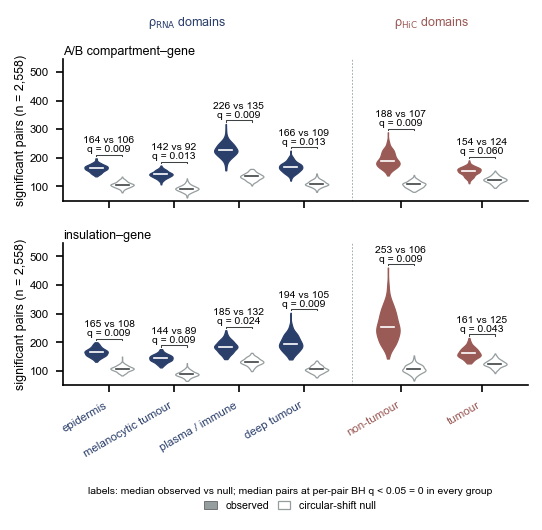

In [18]:
GROUPS = [("RNA", "epidermis"), ("RNA", "melanocytic tumour"), ("RNA", "plasma / immune"), ("RNA", "deep tumour"),
          ("HiC", "non-tumour"), ("HiC", "tumour")]
XPOS = [0, 1, 2, 3, 4.5, 5.75]


def violin(ax, v, x0, colr, filled):
    p = ax.violinplot(v, positions=[x0], widths=0.36, showextrema=False)
    for b in p["bodies"]:
        b.set_facecolor(colr if filled else "white"); b.set_edgecolor(colr if filled else ANCHOR["stone"]); b.set_alpha(1); b.set_linewidth(0.6)
    ax.plot([x0 - 0.1, x0 + 0.1], [np.median(v)] * 2, color="white" if filled else INK, lw=0.8, zorder=3)


fig, axs = plt.subplots(2, 1, figsize=(3.6, 3.4), sharex=True, sharey=True)
fig.subplots_adjust(left=0.13, right=0.99, top=0.9, bottom=0.26, hspace=0.3)
top = gcounts[gcounts.kind == "observed"].n_sig.max()
for ax, (layer, nm) in zip(axs, (("A/B", "A/B compartment–gene"), ("insulation", "insulation–gene"))):
    for (m, dom), x0 in zip(GROUPS, XPOS):
        s_ = gcounts[(gcounts.axis == m) & (gcounts.domain == dom) & (gcounts.layer == layer)]
        o, n = s_[s_.kind == "observed"].n_sig.values, s_[s_.kind == "null"].n_sig.values
        violin(ax, o, x0 - 0.2, AXC[m], True); violin(ax, n, x0 + 0.2, ANCHOR["stone"], False)
        r = gsumm[(gsumm.axis == m) & (gsumm.domain == dom) & (gsumm.layer == layer)].iloc[0]
        h = max(o.max(), n.max()) + 8
        ax.plot([x0 - 0.2, x0 - 0.2, x0 + 0.2, x0 + 0.2], [h, h + 5, h + 5, h], color=INK, lw=0.5)
        ax.text(x0, h + 7, f"{np.median(o):.0f} vs {np.median(n):.0f}\nq = {r.q_bh:.3f}", ha="center", va="bottom", fontsize=5, linespacing=1.0)
    ax.set_title(nm, fontsize=6, pad=2, loc="left"); ax.set_ylabel(f"significant pairs (n = {len(names):,})", labelpad=1, fontsize=6)
    ax.axvline(3.75, color=REFERENCE, lw=0.4, ls=(0, (2, 2))); ax.set_ylim(50, top + 85); ax.tick_params(axis="y", labelsize=5.5)
axs[1].set_xticks(XPOS); axs[1].set_xticklabels([dom for _, dom in GROUPS], rotation=30, ha="right", fontsize=5.5)
for tl, (m, _) in zip(axs[1].get_xticklabels(), GROUPS):
    tl.set_color(AXC[m])
fig.text(0.13 + 0.86 * 1.8 / 6.75, 0.955, f"{SUB['RNA']} domains", color=C_RNA, fontsize=6, ha="center", va="bottom")
fig.text(0.13 + 0.86 * 5.35 / 6.75, 0.955, f"{SUB['HiC']} domains", color=C_HIC, fontsize=6, ha="center", va="bottom")
fig.legend(handles=[Patch(fc=ANCHOR["stone"], ec=INK, lw=0.3, label="observed"), Patch(fc="white", ec=ANCHOR["stone"], lw=0.6, label="circular-shift null")],
           loc="lower center", ncol=2, fontsize=5.1, bbox_to_anchor=(0.55, -0.005), handlelength=1.2, columnspacing=0.8,
           title="labels: median observed vs null; median pairs at per-pair BH q < 0.05 = "
                 + (f"{gsumm.q_obs_median.iloc[0]:g} in every group" if gsumm.q_obs_median.nunique() == 1 else
                    ", ".join(f"{v:g}" for v in gsumm.q_obs_median)), title_fontsize=5)
plt.show()

## Fig. 6h: two example bins along the full isodepth

Chromatin (left axis) and gene score (right axis, noise-matched) over 30 equal-count windows of all spots. Dots are
window means and the line a running mean of 3 windows. P, lag and q are the chromatin → gene test of the per-bin table.

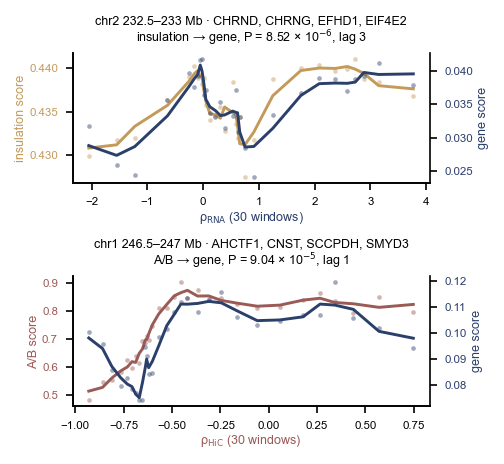

,axis,layer,bin,genes,p_c2g,lag_c2g,q_c2g
3026,RNA,insulation,chr2:232500000-233000000,"CHRND,CHRNG,EFHD1,EIF4E2,GIGYF2,KCNJ13",0.000009,3,0.010892
5380,HiC,A/B,chr1:246500000-247000000,"AHCTF1,CNST,SCCPDH,SMYD3,TFB2M,ZNF670",0.000090,1,0.115602


In [19]:
def pfmt(p):
    if p >= 0.001:
        return f"P = {p:.3f}"
    e = int(np.floor(np.log10(p))); return f"P = {p / 10 ** e:.2f} × 10$^{{{e}}}$".replace("-", "−")


def run3(v):
    o = np.convolve(v, np.ones(3) / 3, mode="same"); o[0], o[-1] = v[:2].mean(), v[-2:].mean(); return o


EX = [("RNA", "insulation", INf, "chr2:232500000-233000000", "insulation score", C_IN),
      ("HiC", "A/B", ABf, "chr1:246500000-247000000", "A/B score", C_AB)]
fig, axs = plt.subplots(2, 1, figsize=(3.4, 3.1)); fig.subplots_adjust(left=0.15, right=0.85, top=0.88, bottom=0.12, hspace=0.72)
for ax, (m, layer, C, b, ylab, colr) in zip(axs, EX):
    j = list(names).index(b); E = np.array_split(np.argsort(d[m]), NBIN); rb = np.array([d[m][e].mean() for e in E])
    cser = np.array([C[e, j].mean() for e in E]); gser = np.array([S25f[e, j].mean() for e in E])
    r = per_bin[(per_bin.axis == m) & (per_bin.layer == layer) & (per_bin.bin == b)].iloc[0]
    ax.scatter(rb, cser, s=5, color=colr, alpha=0.45, lw=0, zorder=2); ax.plot(rb, run3(cser), color=colr, lw=1.4, zorder=3)
    a2 = ax.twinx(); a2.scatter(rb, gser, s=5, color=C_RNA, alpha=0.45, lw=0, zorder=2); a2.plot(rb, run3(gser), color=C_RNA, lw=1.4, zorder=3)
    ax.set_ylabel(ylab, color=colr, labelpad=1, fontsize=6); a2.set_ylabel("gene score", color=C_RNA, labelpad=2, fontsize=6)
    ax.tick_params(axis="y", labelcolor=colr, labelsize=5.5); a2.tick_params(axis="y", labelcolor=C_RNA, labelsize=5.5)
    ax.tick_params(axis="x", labelsize=5.5); a2.spines["right"].set_visible(True)
    ax.set_xlabel(f"{SUB[m]} (30 windows)", color=AXC[m], labelpad=1, fontsize=6)
    ax.text(0.5, 1.2, f"{bin_title(b)} · {', '.join(bin_genes[j].split(',')[:4])}", transform=ax.transAxes, ha="center", va="bottom", fontsize=6)
    ax.text(0.5, 1.04, f"{layer} → gene, {pfmt(r.p_c2g)}, lag {int(r.lag_c2g)}", transform=ax.transAxes, ha="center", va="bottom", fontsize=6)
plt.show()
pd.concat([per_bin[(per_bin.axis == m) & (per_bin.layer == layer) & (per_bin.bin == b)] for m, layer, _, b, _, _ in EX])[["axis", "layer", "bin", "genes", "p_c2g", "lag_c2g", "q_c2g"]]